# Does the Django app give the same predictions as the notebook?

Task 6 asks us to *confirm the app's prediction matches what the model gives directly in a notebook*.
This notebook does exactly that, on the 11-row hold-out from the Preprocessing task (2026-09-20 → 2026-10-10):

1. call each saved model **directly** with the rows of `cairo_weather_model_ready_2day.csv` (how a notebook would use it);
2. call the **app's own prediction function** (`forecast.ml.predictor.forecast`, the code behind both the web form and `/api/predict/`) with the six raw inputs a user would type;
3. compare the two. The difference must be zero (to floating-point precision).


In [1]:
import os, sys, json
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
os.environ["DJANGO_SETTINGS_MODULE"] = "config.settings"

import django; django.setup()                     # loads the models exactly like the server does at start-up

import joblib, numpy as np, pandas as pd, matplotlib.pyplot as plt
from django.conf import settings
from forecast.ml import history
from forecast.ml.features import FEATURE_ORDER, TARGET
from forecast.ml.predictor import forecast, get_registry

registry = get_registry().ensure_loaded()
meta = registry.meta
print("Models in the app:", list(registry.models))
print("Hold-out:", meta["holdout"])

Loaded 3 models: ridge, random_forest, gradient_boosting


Models in the app: ['ridge', 'random_forest', 'gradient_boosting']
Hold-out: {'rows': 11, 'start': '2026-09-20', 'end': '2026-10-10'}


## 1. The notebook way: call the saved models directly

In [2]:
model_ready = pd.read_csv(settings.DATA_DIR / "cairo_weather_model_ready_2day.csv", parse_dates=["date"]).set_index("date")
split = model_ready.index.max() - pd.Timedelta(days=21)
test = model_ready[model_ready.index > split]

direct = {}
for key, info in meta["models"].items():
    model = joblib.load(settings.ARTIFACTS_DIR / info["file"])          # a fresh copy, independent of the app
    direct[key] = pd.Series(model.predict(test[FEATURE_ORDER]), index=test.index)
direct = pd.DataFrame(direct); direct.insert(0, "actual", test[TARGET])
direct.round(2)

,actual,ridge,random_forest,gradient_boosting
date,,,,
2026-09-20,27.26,28.22,28.63,28.71
2026-09-22,27.34,27.48,27.76,28.06
2026-09-24,27.96,27.29,27.35,28.01
2026-09-26,25.67,27.30,27.68,27.55
2026-09-28,27.00,26.26,26.26,26.04
2026-09-30,25.25,26.62,26.58,26.42
2026-10-02,25.53,25.76,25.65,25.40
2026-10-04,24.22,25.63,25.78,25.23
2026-10-06,24.17,24.88,24.67,24.79


## 2. The app way: the six raw inputs a user would type

For each hold-out date the six values the form asks for (temperature 2 days / 24 days / 1 year before and the three averages) are read from the history and sent through the app's `forecast()` function,
which builds the features (`day_of_year` sin/cos + lags + rolling means), applies the model and adds the interval.

In [3]:
rows = {}
for ts in test.index:
    d = ts.date()
    inputs = history._inputs_at(history._position(d), decimals=None)      # full precision, same as the notebook
    rows[ts] = {key: forecast(key, d, inputs).value for key in registry.models}
app = pd.DataFrame(rows).T
app.insert(0, "actual", test[TARGET])
app.round(2)

,actual,ridge,random_forest,gradient_boosting
2026-09-20,27.26,28.22,28.63,28.71
2026-09-22,27.34,27.48,27.76,28.06
2026-09-24,27.96,27.29,27.35,28.01
2026-09-26,25.67,27.30,27.68,27.55
2026-09-28,27.00,26.26,26.26,26.04
2026-09-30,25.25,26.62,26.58,26.42
2026-10-02,25.53,25.76,25.65,25.40
2026-10-04,24.22,25.63,25.78,25.23
2026-10-06,24.17,24.88,24.67,24.79
2026-10-08,24.94,24.64,24.72,24.17


## 3. Compare

In [4]:
diff = (app.drop(columns="actual") - direct.drop(columns="actual")).abs()
print("Largest absolute difference between app and notebook predictions (°C):")
print(diff.max().to_string())
assert diff.to_numpy().max() < 1e-9, "app and notebook disagree!"
print("\nIDENTICAL: the app reproduces the notebook's predictions on all", len(test), "hold-out rows for", len(registry.models), "models.")

Largest absolute difference between app and notebook predictions (°C):
ridge                3.552714e-15
random_forest        0.000000e+00
gradient_boosting    0.000000e+00

IDENTICAL: the app reproduces the notebook's predictions on all 11 hold-out rows for 3 models.


### What a user sees on the page
The default model (Ridge regression) with its approximate 80% range, next to the observed values.

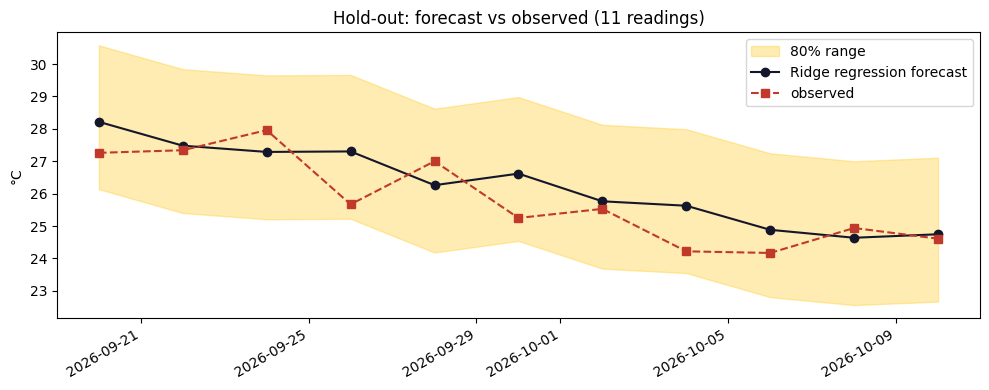

100% of the 11 observed values fall inside the 80% range (only 11 points, so treat this as a sanity check).


In [5]:
key = meta["default_model"]; q = meta["models"][key]["residual_quantiles"]
fig, ax = plt.subplots(figsize=(10, 4))
ax.fill_between(app.index, app[key] + q["q10"], app[key] + q["q90"], color="#ffc300", alpha=.3, label="80% range")
ax.plot(app.index, app[key], "o-", color="#14172b", label=f'{meta["models"][key]["label"]} forecast')
ax.plot(app.index, app["actual"], "s--", color="#c0392b", label="observed")
ax.set_ylabel("°C"); ax.set_title("Hold-out: forecast vs observed (11 readings)"); ax.legend(); fig.autofmt_xdate(); plt.tight_layout(); plt.show()
inside = ((app["actual"] >= app[key] + q["q10"]) & (app["actual"] <= app[key] + q["q90"])).mean()
print(f"{inside:.0%} of the 11 observed values fall inside the 80% range (only 11 points, so treat this as a sanity check).")

## Model comparison (time-series cross-validation on the training rows, then the hold-out)

In [6]:
table = pd.DataFrame({**{k: {"CV MAE (°C)": v["cv_mae"], "Hold-out MAE (°C)": v["holdout_mae"]} for k, v in meta["models"].items()},
                      **{k: {"CV MAE (°C)": v["cv_mae"], "Hold-out MAE (°C)": v["holdout_mae"]} for k, v in meta["baselines"].items()}}).T
table.index = [meta["models"].get(k, meta["baselines"].get(k))["label"] for k in table.index]
table.round(3).sort_values("CV MAE (°C)")

,CV MAE (°C),Hold-out MAE (°C)
Ridge regression,1.391,0.755
Random forest,1.563,0.842
Persistence (same as 2 days ago),1.592,0.916
Gradient boosting,1.643,0.851
Seasonal naive (same day last year),2.284,0.916


**Reading the table.** Cross-validation uses 5 expanding time-ordered folds over ~860 readings (about 14 months per fold), so it is far more trustworthy than the 11-row hold-out.
Ridge regression has the lowest CV error and beats the naive baselines, so it is the default in the app; the other two models are offered in the dropdown.
The hold-out error is smaller than the CV error because those 11 autumn days are calm and easy to predict.